<a href="https://colab.research.google.com/github/Chaki34/customer-churn-analysis-prediction/blob/main/ustomer%20Churn%20Analysis%20%26%20Prediction%20%20-%20%20Data%20Analytics%2C%20Data%20Mining%20%26%20Visualization%20using%20Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Our learning roadmap

We'll build the project in this order:

01 → Load dataset
02 → Understand the dataset
03 → Basic Pandas operations
04 → Data cleaning
05 → NumPy statistical analysis
06 → Univariate analysis
07 → Bivariate analysis
08 → Matplotlib visualizations
09 → Customer churn analysis
10 → Find important churn factors
11 → Feature engineering
12 → Data preprocessing
13 → ML prediction
14 → Evaluate the model
15 → Final business recommendations

In [54]:
!pip install -q kaggle

In [55]:
!kaggle datasets download -d blastchar/telco-customer-churn

Dataset URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
License(s): copyright-authors
telco-customer-churn.zip: Skipping, found more recently modified local copy (use --force to force download)


In [56]:
!unzip -o telco-customer-churn.zip

Archive:  telco-customer-churn.zip
  inflating: WA_Fn-UseC_-Telco-Customer-Churn.csv  


In [57]:
!ls

sample_data  telco-customer-churn.zip  WA_Fn-UseC_-Telco-Customer-Churn.csv


In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Pandas      → data manipulation#
#NumPy       → numerical analysis#
#Matplotlib  → visualization#


In [59]:
df = pd.read_csv(
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

In [60]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [61]:
df.shape # check dataset size
#7043 → customers/rows#
#21   → columns#

(7043, 21)

In [62]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [63]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [64]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [66]:
# stats

df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [67]:
# Let's analyze MonthlyCharges

monthly_charges = df["MonthlyCharges"].values # .values for  get only values as tuple

In [68]:
print("Mean:", np.mean(monthly_charges))
print("Median:", np.median(monthly_charges))
print("Minimum:", np.min(monthly_charges))
print("Maximum:", np.max(monthly_charges))
print("Standard Deviation:", np.std(monthly_charges))

Mean: 64.76169246059918
Median: 70.35
Minimum: 18.25
Maximum: 118.75
Standard Deviation: 30.087910854936975


In [69]:
#Analyze Churn

df["Churn"].unique()

# Count them:

df["Churn"].value_counts()

# cal parcentage

churn_counts = df["Churn"].value_counts()

churn_percentage = (
    churn_counts / len(df)
) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64


In [70]:
#Use NumPy to calculate churn

churned = np.sum(
    df["Churn"].values == "Yes"
)

total_customers = len(df)

churn_rate = (
    churned / total_customers
) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned)
print("Churn Rate:", churn_rate, "%")

df["Churn"].values == "Yes" # bool numpy array

np.sum(df["Churn"].values == "Yes") # count

Total Customers: 7043
Churned Customers: 1869
Churn Rate: 26.536987079369588 %


np.int64(1869)

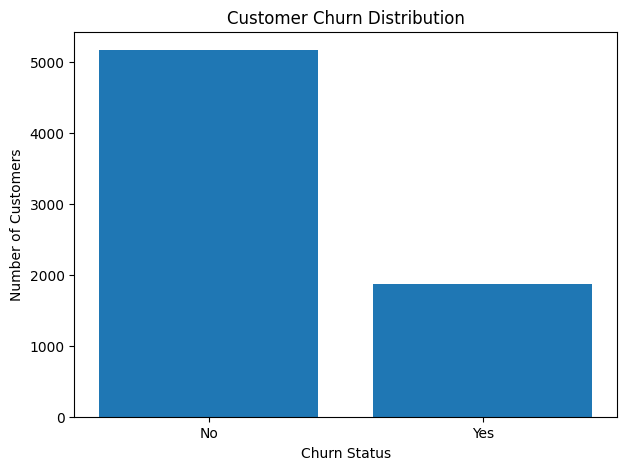

In [71]:
# visual  1 :

churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    churn_counts.index,
    churn_counts.values
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [72]:
# Identify Numerical and Categorical Variables

numeric_columns = df.select_dtypes(
    include=np.number
).columns

print(numeric_columns)

categorical_columns = df.select_dtypes(
    include="object"
).columns

print(categorical_columns)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='object')
Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='object')


In [73]:
# Data Quality Analysis
missing_values = df.isnull().sum()

print(missing_values)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [74]:
# find blank slots

total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

total_charges_numeric.isnull().sum()

np.int64(11)

In [75]:

#Clean TotalCharges
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"].dtype

dtype('float64')

In [76]:
# handle missing values

df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [77]:
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

In [78]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [79]:
# Duplicate Analysis
df.duplicated().sum()

df = df.drop_duplicates()

In [80]:
#Check Unique Values

for column in df.columns:
    unique_values = df[column].unique()
    print(f"Unique values in {column}:")
    print(unique_values)
    print()

Unique values in customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

Unique values in gender:
['Female' 'Male']

Unique values in SeniorCitizen:
[0 1]

Unique values in Partner:
['Yes' 'No']

Unique values in Dependents:
['No' 'Yes']

Unique values in tenure:
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]

Unique values in PhoneService:
['No' 'Yes']

Unique values in MultipleLines:
['No phone service' 'No' 'Yes']

Unique values in InternetService:
['DSL' 'Fiber optic' 'No']

Unique values in OnlineSecurity:
['No' 'Yes' 'No internet service']

Unique values in OnlineBackup:
['Yes' 'No' 'No internet service']

Unique values in DeviceProtection:
['No' 'Yes' 'No internet service']

Unique values in TechSupport:
['No' 'Yes' 'No internet service']

Unique values in Streami

In [81]:
# Create Churn Numerical Variable

df["ChurnValue"] = np.where(
    df["Churn"] == "Yes",
    1,
    0
)

df[["Churn", "ChurnValue"]].head()

,Churn,ChurnValue
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


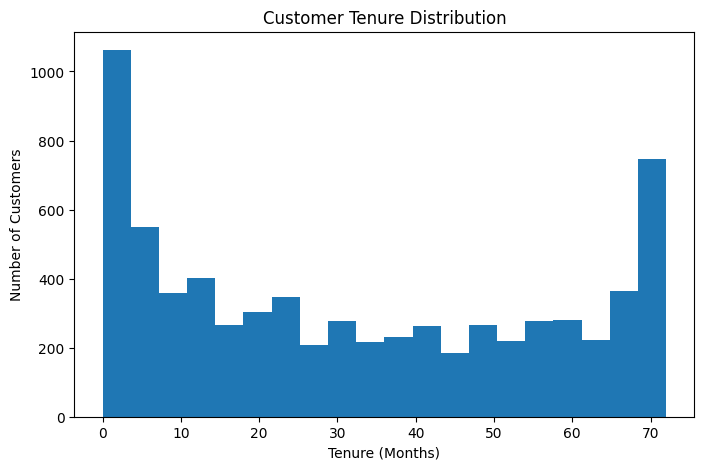

In [82]:
# Univariate Analysis

plt.figure(figsize=(8,5))

plt.hist(
    df["tenure"],
    bins=20
)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

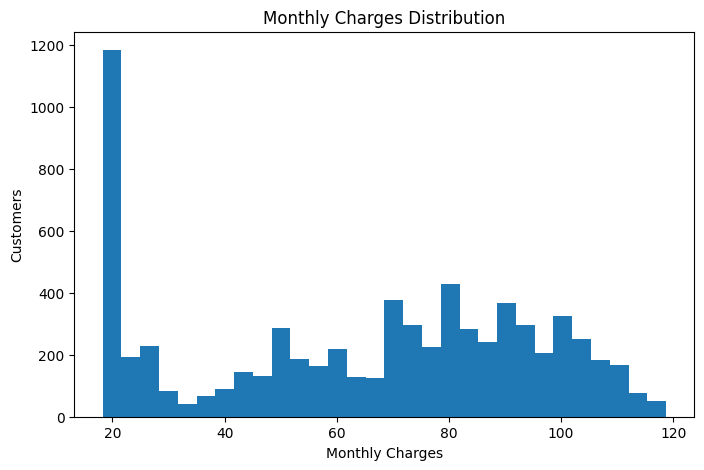

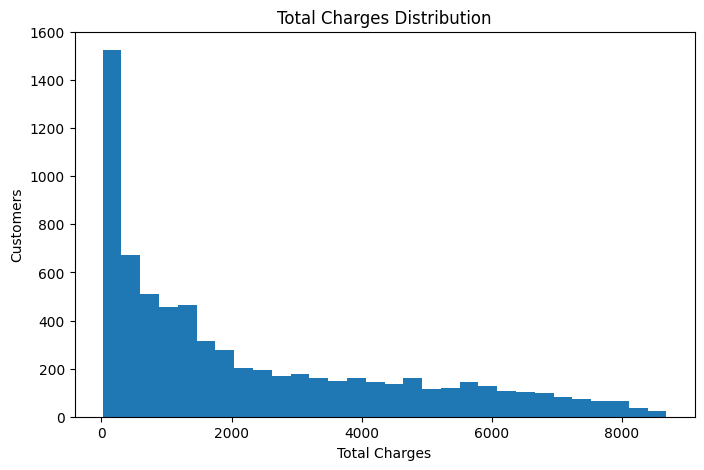

In [83]:
#Monthly Charges Distribution
plt.figure(figsize=(8,5))

plt.hist(
    df["MonthlyCharges"],
    bins=30
)

plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Customers")

plt.show()

# total charge distribution

plt.figure(figsize=(8,5))

plt.hist(
    df["TotalCharges"],
    bins=30
)

plt.title("Total Charges Distribution")
plt.xlabel("Total Charges")
plt.ylabel("Customers")

plt.show()

In [84]:
tenure = df["tenure"].values
monthly = df["MonthlyCharges"].values
total = df["TotalCharges"].values

print("Tenure Mean:", np.mean(tenure))
print("Tenure Median:", np.median(tenure))
print("Tenure Min:", np.min(tenure))
print("Tenure Max:", np.max(tenure))
print("Tenure Std:", np.std(tenure))

print("---------------------")

print("Monthly Mean:", np.mean(monthly))
print("Monthly Median:", np.median(monthly))
print("Monthly Min:", np.min(monthly))
print("Monthly Max:", np.max(monthly))
print("Monthly Std:", np.std(monthly))

Tenure Mean: 32.37114865824223
Tenure Median: 29.0
Tenure Min: 0
Tenure Max: 72
Tenure Std: 24.55773742286344
---------------------
Monthly Mean: 64.76169246059918
Monthly Median: 70.35
Monthly Min: 18.25
Monthly Max: 118.75
Monthly Std: 30.087910854936975


Churn     No  Yes
gender           
Female  2549  939
Male    2625  930


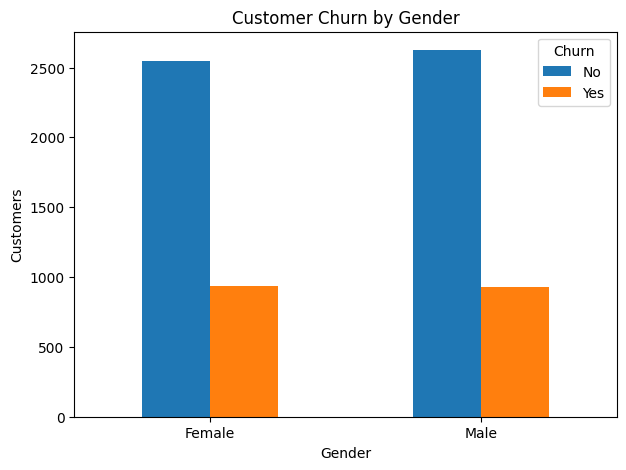

In [85]:
#Bivariate Analysis
# Study the relationship between two variables.


# 1. Churn vs Gender
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"]
)

print(gender_churn)

gender_churn.plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Customers")

plt.xticks(rotation=0)

plt.show()

Churn            No   Yes
SeniorCitizen            
0              4508  1393
1               666   476


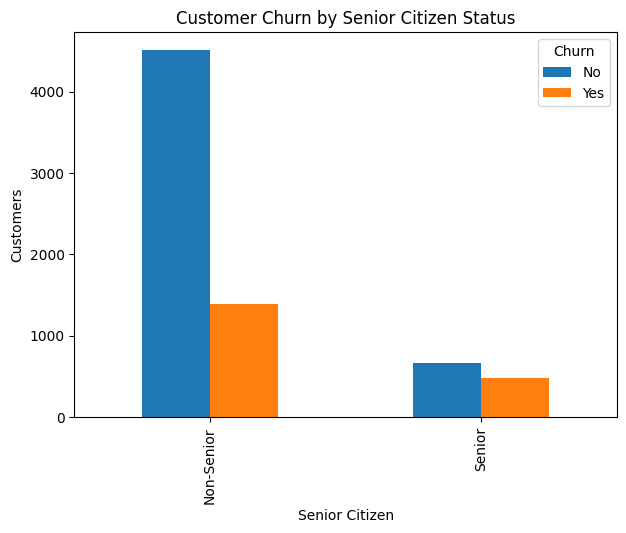

In [86]:
# 2. Churn vs Senior Citizen

senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"]
)

print(senior_churn)

senior_churn.plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Customers")

plt.xticks(
    [0, 1],
    ["Non-Senior", "Senior"]
)

plt.show()

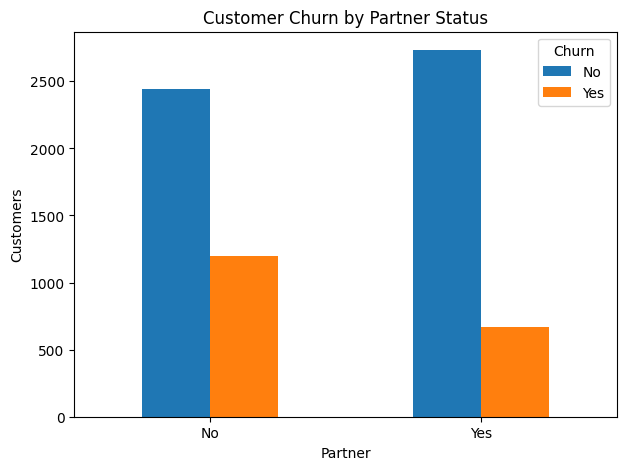

In [87]:

# Churn vs Partner
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"]
)

partner_churn.plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Customer Churn by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Customers")

plt.xticks(rotation=0)

plt.show()

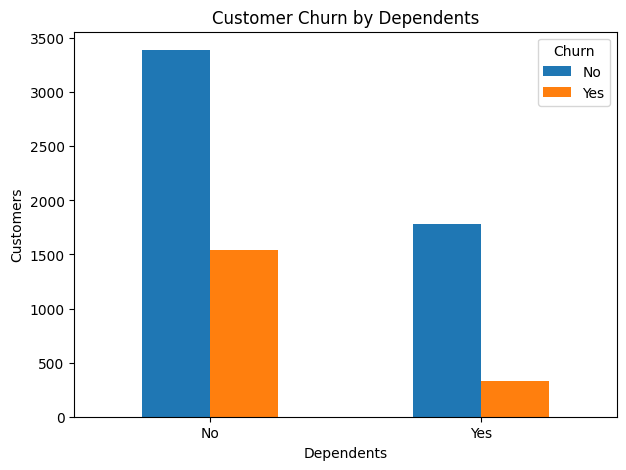

In [88]:

# 3.Churn vs Dependents
dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"]
)

dependents_churn.plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Customer Churn by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Customers")

plt.xticks(rotation=0)

plt.show()

Churn              No   Yes
InternetService            
DSL              1962   459
Fiber optic      1799  1297
No               1413   113


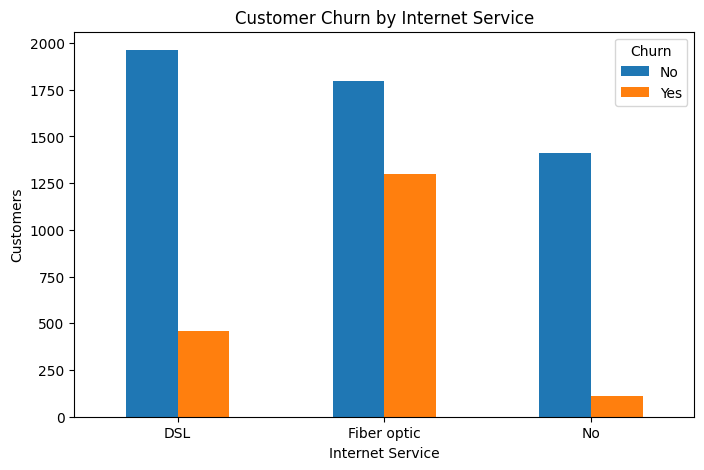

In [89]:
# 4. Churn vs Internet Service

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"]
)

print(internet_churn)

internet_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Customers")

plt.xticks(rotation=0)

plt.show()

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


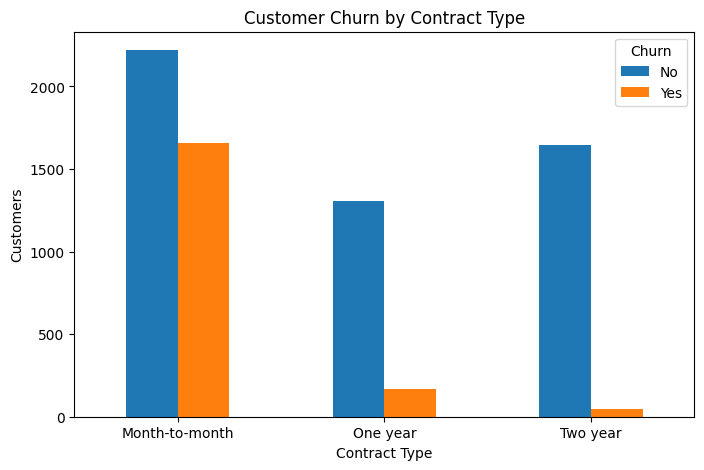

In [90]:
# Churn vs Contract

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print(contract_churn)

contract_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Customers")

plt.xticks(rotation=0)

plt.show()

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


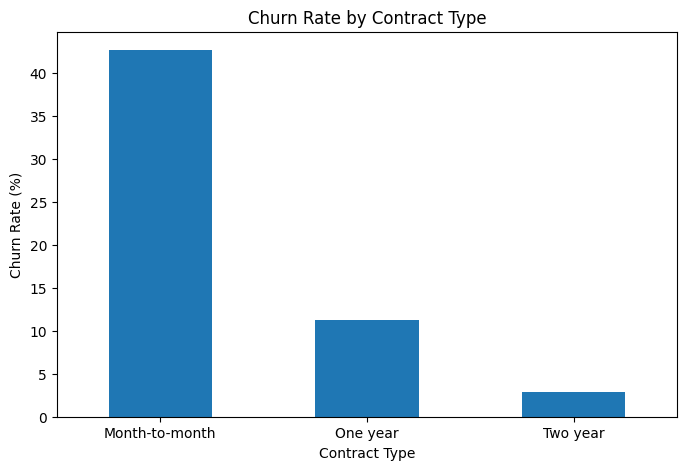

In [91]:
# Calculate Actual Churn Rate by Contract

contract_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_rate)

contract_rate["Yes"].plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)

plt.show()

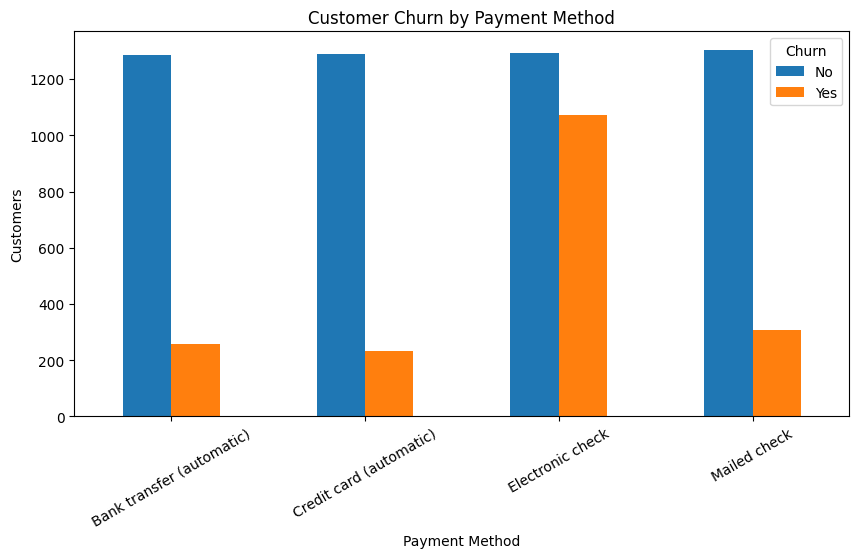

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


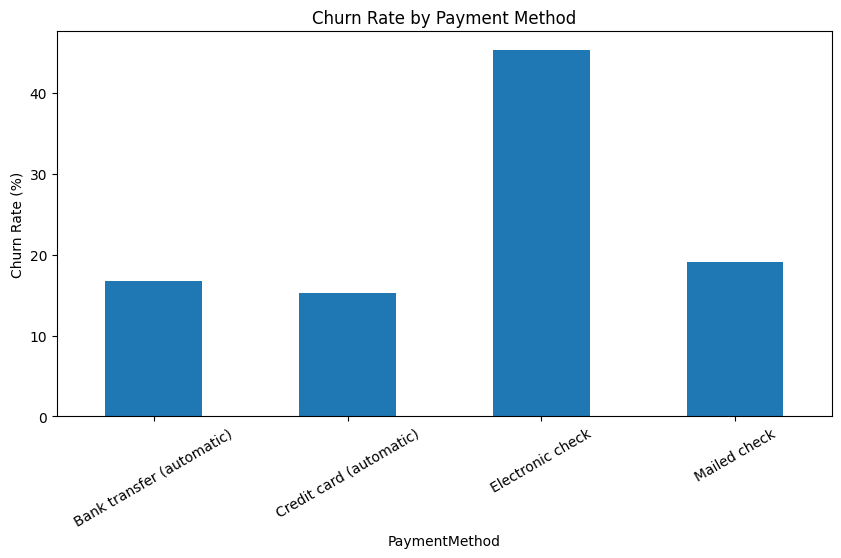

In [92]:
# Churn vs Payment Method

payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

payment_churn.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Customers")

plt.xticks(rotation=30)

plt.show()

# Calculate Payment Method Churn Rate

payment_rate = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_rate)

payment_rate["Yes"].plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Churn Rate by Payment Method")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=30)

plt.show()

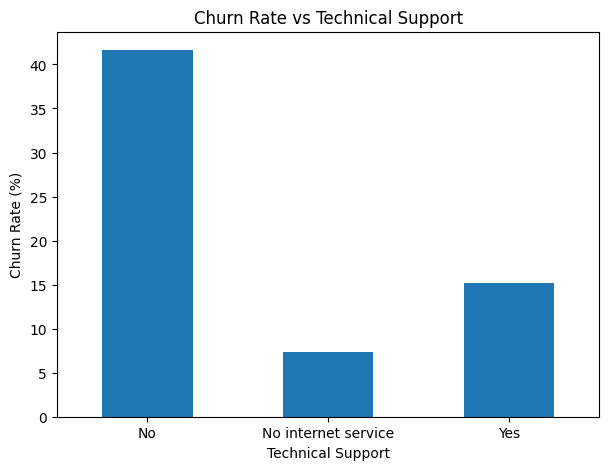

In [93]:
# Churn vs Tech Support

support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"]
)

support_rate = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

support_rate["Yes"].plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Churn Rate vs Technical Support")
plt.xlabel("Technical Support")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)

plt.show()

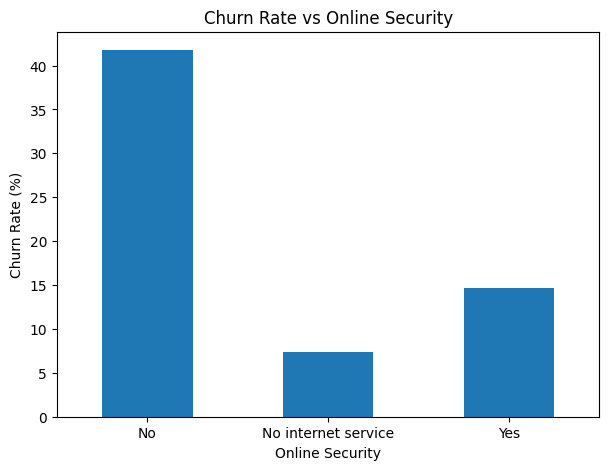

In [94]:
# Churn vs Online Security

security_rate = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

security_rate["Yes"].plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Churn Rate vs Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)

plt.show()

In [95]:
# Correlation Analysis

numeric_df = df[
    [
        "SeniorCitizen",
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "ChurnValue"
    ]
]

correlation_matrix = numeric_df.corr()

print(correlation_matrix)

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges  \
SeniorCitizen        1.000000  0.016567        0.220173      0.102652   
tenure               0.016567  1.000000        0.247900      0.825464   
MonthlyCharges       0.220173  0.247900        1.000000      0.650864   
TotalCharges         0.102652  0.825464        0.650864      1.000000   
ChurnValue           0.150889 -0.352229        0.193356     -0.199037   

                ChurnValue  
SeniorCitizen     0.150889  
tenure           -0.352229  
MonthlyCharges    0.193356  
TotalCharges     -0.199037  
ChurnValue        1.000000  


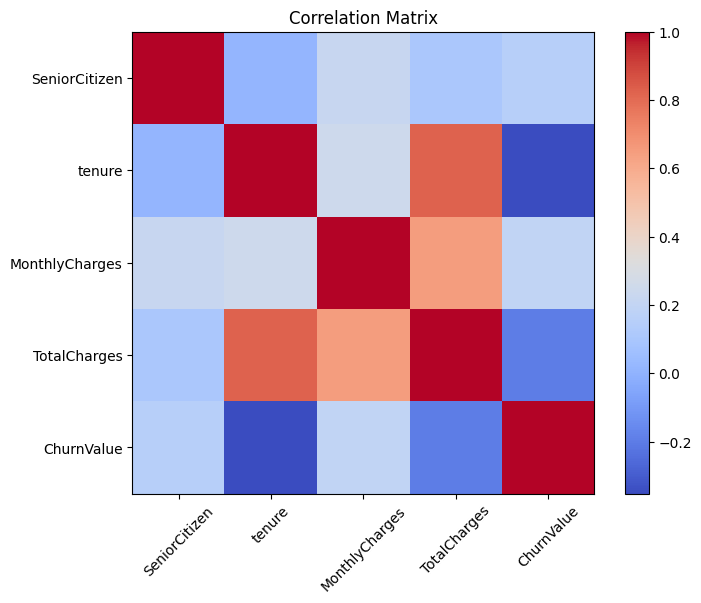

In [96]:
# Visualize Correlation Using Matplotlib

plt.figure(figsize=(8,6))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix")

plt.show()

In [97]:
# Data Mining — Find High-Risk Customer Groups

# This is a simple example of rule-based customer segmentation.
high_risk = df[
    (df["Contract"] == "Month-to-month") &
    (df["tenure"] <= 12) &
    (df["MonthlyCharges"] > df["MonthlyCharges"].median())
]

print(
    "Potential High-Risk Customers:",
    len(high_risk)
)

high_risk_churn = (
    high_risk["ChurnValue"].mean()
) * 100

print(
    "High-Risk Group Churn Rate:",
    round(high_risk_churn, 2),
    "%"
)

# Compare High-Risk Group with Overall Population


# If the high-risk group's rate is substantially higher, you have discovered a potentially useful business segment.
print(
    "Overall Churn Rate:",
    round(churn_rate, 2),
    "%"
)

print(
    "High-Risk Churn Rate:",
    round(high_risk_churn, 2),
    "%"
)

Potential High-Risk Customers: 812
High-Risk Group Churn Rate: 69.95 %
Overall Churn Rate: 26.54 %
High-Risk Churn Rate: 69.95 %


In [98]:
# Find High-Value Customers

high_value = df[
    df["MonthlyCharges"] >
    df["MonthlyCharges"].quantile(0.75)
]

print(
    "High-Value Customers:",
    len(high_value)
)

high_value_churn = (
    high_value["ChurnValue"].mean()
) * 100

print(
    "High-Value Customer Churn:",
    round(high_value_churn, 2),
    "%"
)

High-Value Customers: 1758
High-Value Customer Churn: 32.88 %


In [99]:
# Create a Customer Risk Score

df["RiskScore"] = (
    (df["Contract"] == "Month-to-month").astype(int)
    +
    (df["tenure"] <= 12).astype(int)
    +
    (df["MonthlyCharges"] > df["MonthlyCharges"].median()).astype(int)
    +
    (df["TechSupport"] == "No").astype(int)
)

df["RiskScore"].value_counts().sort_index()

,count
RiskScore,
0,1267
1,1629
2,1732
3,1704
4,711


In [100]:
# Analyze risk score vs. churn
risk_analysis = pd.crosstab(
    df["RiskScore"],
    df["Churn"],
    normalize="index"
) * 100

print(risk_analysis.round(2))

Churn         No    Yes
RiskScore              
0          97.79   2.21
1          91.53   8.47
2          77.89  22.11
3          52.52  47.48
4          28.13  71.87


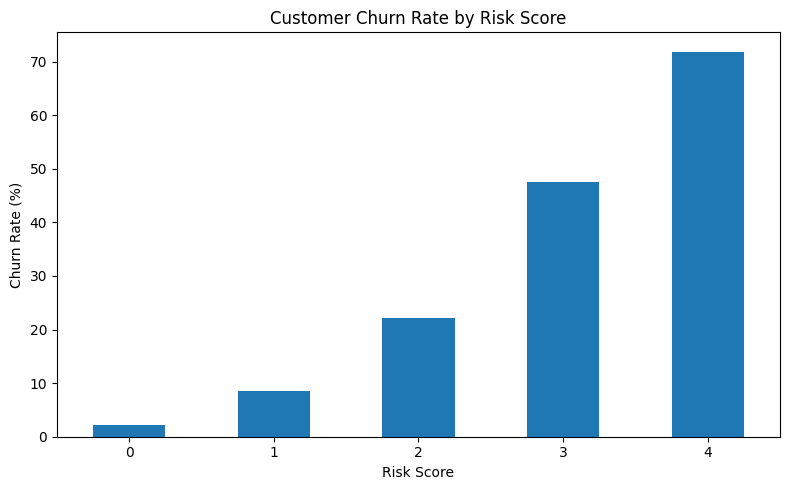

In [101]:
# Visualize the churn rate by risk score
risk_analysis["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Churn Rate by Risk Score")
plt.xlabel("Risk Score")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [102]:
# Identify high-risk customers
high_risk_customers = df[df["RiskScore"] >= 3]

print("High-risk customers:", len(high_risk_customers))
display(
    high_risk_customers[
        ["customerID", "Contract", "tenure",
         "MonthlyCharges", "TechSupport", "RiskScore", "Churn"]
    ].head(20)
)

High-risk customers: 2415


,customerID,Contract,tenure,MonthlyCharges,TechSupport,RiskScore,Churn
0,7590-VHVEG,Month-to-month,1,29.85,No,3,No
2,3668-QPYBK,Month-to-month,2,53.85,No,3,Yes
4,9237-HQITU,Month-to-month,2,70.70,No,4,Yes
5,9305-CDSKC,Month-to-month,8,99.65,No,4,Yes
6,1452-KIOVK,Month-to-month,22,89.10,No,3,No
7,6713-OKOMC,Month-to-month,10,29.75,No,3,No
13,0280-XJGEX,Month-to-month,49,103.70,No,3,Yes
19,4183-MYFRB,Month-to-month,21,90.05,No,3,No
20,8779-QRDMV,Month-to-month,1,39.65,No,3,Yes
26,6467-CHFZW,Month-to-month,47,99.35,No,3,Yes


In [103]:
# Data Mining Insights
# Identify churn rates by contract type
contract_analysis = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Contract Type:")
print(contract_analysis.round(2))

# Identify churn rates by internet service
internet_analysis = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Rate by Internet Service:")
print(internet_analysis.round(2))

# Identify churn rates by technical support
support_analysis = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Rate by Tech Support:")
print(support_analysis.round(2))

Churn Rate by Contract Type:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83

Churn Rate by Internet Service:
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

Churn Rate by Tech Support:
Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


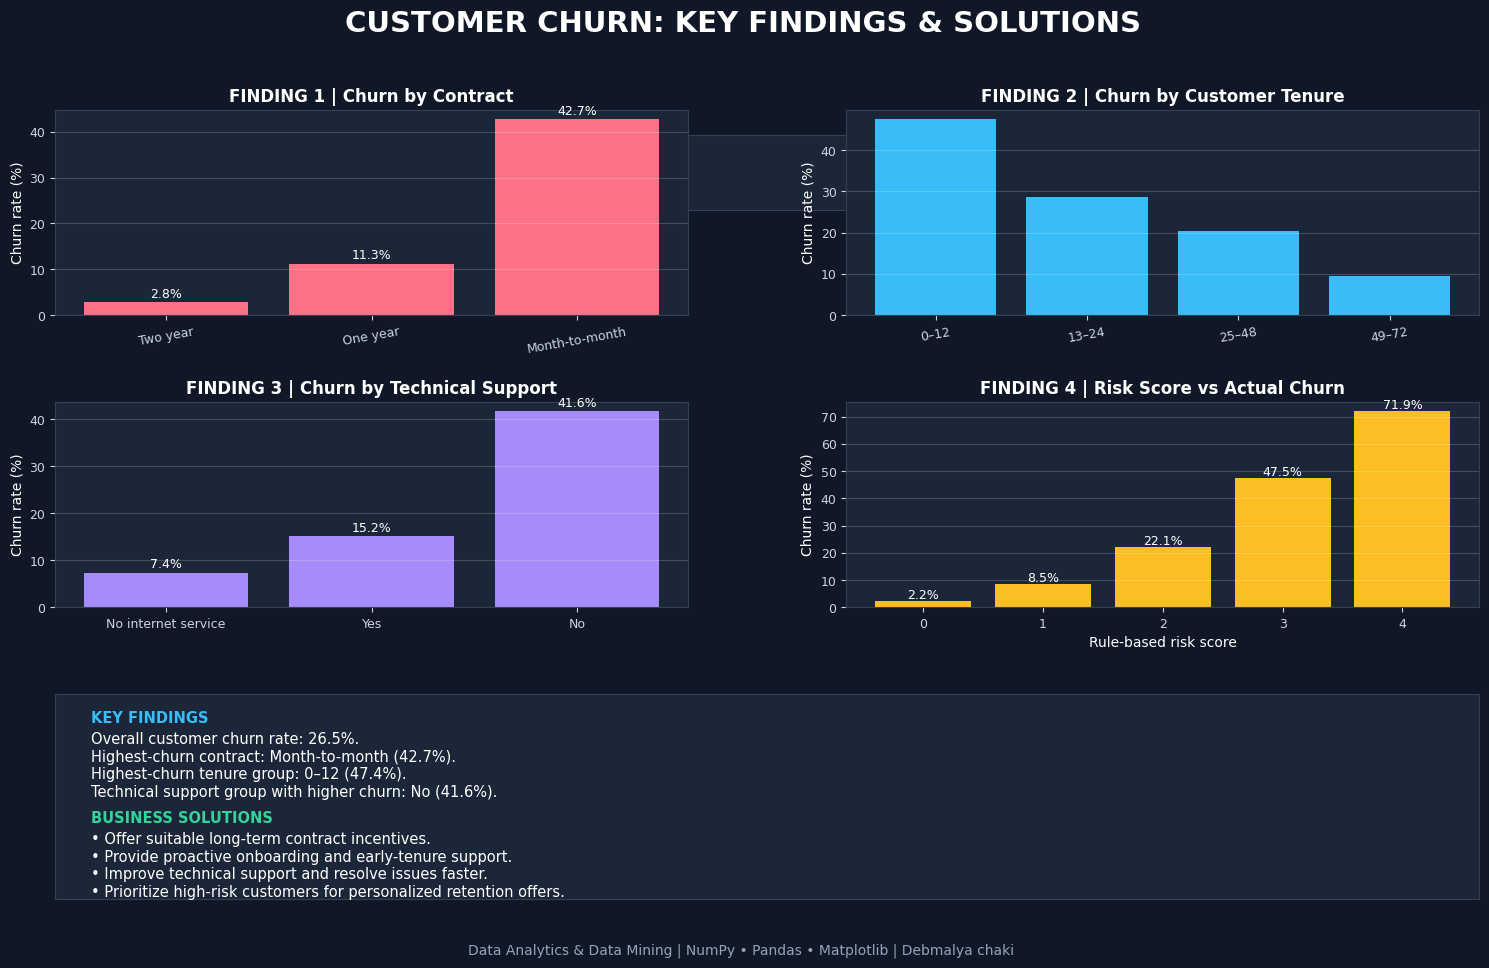

Saved: customer_churn_findings_dashboard.png


In [105]:

# FINAL DASHBOARD: CUSTOMER CHURN FINDINGS & SOLUTIONS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare data
data = df.copy()
data["ChurnValue"] = (data["Churn"] == "Yes").astype(int)

total = len(data)
churned = data["ChurnValue"].sum()
retained = total - churned
churn_rate = churned / total * 100 if total else 0

# Calculate findings from actual data
contract = (
    data.groupby("Contract")["ChurnValue"].mean().mul(100).sort_values()
    if "Contract" in data.columns else pd.Series(dtype=float)
)

tenure_group = pd.cut(
    data["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12", "13–24", "25–48", "49–72"]
) if "tenure" in data.columns else None

tenure_rates = (
    data.assign(TenureGroup=tenure_group)
    .groupby("TenureGroup", observed=False)["ChurnValue"].mean().mul(100)
    if tenure_group is not None else pd.Series(dtype=float)
)

support = (
    data.groupby("TechSupport")["ChurnValue"].mean().mul(100).sort_values()
    if "TechSupport" in data.columns else pd.Series(dtype=float)
)

risk_rates = (
    data.groupby("RiskScore")["ChurnValue"].mean().mul(100).sort_index()
    if "RiskScore" in data.columns else pd.Series(dtype=float)
)

# Single-sheet dashboard
plt.style.use("dark_background")
fig = plt.figure(figsize=(16, 10), facecolor="#101827")
fig.suptitle(
    "CUSTOMER CHURN: KEY FINDINGS & SOLUTIONS",
    fontsize=21, fontweight="bold", color="white", y=0.97
)

gs = fig.add_gridspec(
    3, 2, left=0.07, right=0.96, top=0.87, bottom=0.08,
    hspace=0.42, wspace=0.25
)

# KPI cards
kpi_ax = fig.add_axes([0.08, 0.77, 0.84, 0.075])
kpi_ax.set_facecolor("#1B2638")
kpi_ax.set_xticks([])
kpi_ax.set_yticks([])
for spine in kpi_ax.spines.values():
    spine.set_color("#334155")

kpis = [
    ("TOTAL CUSTOMERS", f"{total:,}", "#38BDF8"),
    ("CHURNED", f"{churned:,}", "#FB7185"),
    ("RETAINED", f"{retained:,}", "#34D399"),
    ("CHURN RATE", f"{churn_rate:.1f}%", "#FBBF24")
]

for i, (label, value, color) in enumerate(kpis):
    x = (i + 0.5) / 4
    kpi_ax.text(x, 0.68, label, ha="center", color="#CBD5E1",
                fontsize=10, transform=kpi_ax.transAxes)
    kpi_ax.text(x, 0.20, value, ha="center", color=color,
                fontsize=19, fontweight="bold",
                transform=kpi_ax.transAxes)

def style(ax, title):
    ax.set_facecolor("#1B2638")
    ax.set_title(title, color="white", fontsize=12, fontweight="bold")
    ax.tick_params(colors="#CBD5E1", labelsize=9)
    ax.grid(axis="y", alpha=0.18)
    for s in ax.spines.values():
        s.set_color("#334155")

# 1. Contract churn — strongest contract pattern
ax1 = fig.add_subplot(gs[0, 0])
style(ax1, "FINDING 1 | Churn by Contract")

if not contract.empty:
    bars = ax1.bar(contract.index.astype(str), contract.values,
                   color="#FB7185")
    ax1.set_ylabel("Churn rate (%)")
    for bar, value in zip(bars, contract.values):
        ax1.text(bar.get_x() + bar.get_width()/2, value + 1,
                 f"{value:.1f}%", ha="center", fontsize=9)
    ax1.tick_params(axis="x", rotation=10)

# 2. Early-tenure churn
ax2 = fig.add_subplot(gs[0, 1])
style(ax2, "FINDING 2 | Churn by Customer Tenure")

if not tenure_rates.empty:
    ax2.bar(tenure_rates.index.astype(str), tenure_rates.values,
            color="#38BDF8")
    ax2.set_ylabel("Churn rate (%)")
    ax2.tick_params(axis="x", rotation=10)

# 3. Technical support
ax3 = fig.add_subplot(gs[1, 0])
style(ax3, "FINDING 3 | Churn by Technical Support")

if not support.empty:
    bars = ax3.bar(support.index.astype(str), support.values,
                   color="#A78BFA")
    ax3.set_ylabel("Churn rate (%)")
    for bar, value in zip(bars, support.values):
        ax3.text(bar.get_x() + bar.get_width()/2, value + 1,
                 f"{value:.1f}%", ha="center", fontsize=9)

# 4. Risk score
ax4 = fig.add_subplot(gs[1, 1])
style(ax4, "FINDING 4 | Risk Score vs Actual Churn")

if not risk_rates.empty:
    bars = ax4.bar(risk_rates.index.astype(str), risk_rates.values,
                   color="#FBBF24")
    ax4.set_xlabel("Rule-based risk score")
    ax4.set_ylabel("Churn rate (%)")
    for bar, value in zip(bars, risk_rates.values):
        ax4.text(bar.get_x() + bar.get_width()/2, value + 1,
                 f"{value:.1f}%", ha="center", fontsize=9)
else:
    ax4.text(0.5, 0.5, "Run the RiskScore cell first",
             ha="center", color="white", transform=ax4.transAxes)

# 5. Findings and solutions panel
ax5 = fig.add_subplot(gs[2, :])
ax5.set_facecolor("#1B2638")
ax5.set_xticks([])
ax5.set_yticks([])
for s in ax5.spines.values():
    s.set_color("#334155")

findings = [
    ("KEY FINDINGS", "#38BDF8"),
    (f"Overall customer churn rate: {churn_rate:.1f}%.", "white")
]

if not contract.empty:
    findings.append((
        f"Highest-churn contract: {contract.idxmax()} "
        f"({contract.max():.1f}%).", "white"
    ))

if not tenure_rates.empty and tenure_rates.notna().any():
    findings.append((
        f"Highest-churn tenure group: {tenure_rates.idxmax()} "
        f"({tenure_rates.max():.1f}%).", "white"
    ))

if not support.empty:
    findings.append((
        f"Technical support group with higher churn: "
        f"{support.idxmax()} ({support.max():.1f}%).", "white"
    ))

findings.extend([
    ("", "white"),
    ("BUSINESS SOLUTIONS", "#34D399"),
    ("• Offer suitable long-term contract incentives.", "white"),
    ("• Provide proactive onboarding and early-tenure support.", "white"),
    ("• Improve technical support and resolve issues faster.", "white"),
    ("• Prioritize high-risk customers for personalized retention offers.", "white")
])

left_x = 0.025
y = 0.92
for text, color in findings:
    if text == "":
        y -= 0.04
        continue
    ax5.text(left_x, y, text, transform=ax5.transAxes,
             color=color, fontsize=10.5,
             fontweight="bold" if color != "white" else "normal",
             va="top")
    y -= 0.105 if text in ("KEY FINDINGS", "BUSINESS SOLUTIONS") else 0.085

fig.text(
    0.5, 0.025,
    "Data Analytics & Data Mining | NumPy • Pandas • Matplotlib | Debmalya chaki ",
    ha="center", color="#94A3B8", fontsize=10
)

plt.show()

# Save dashboard image
fig.savefig(
    "customer_churn_findings_dashboard.png",
    dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor()
)
print("Saved: customer_churn_findings_dashboard.png")

# Project Conclusion

The **Customer Churn Analysis and Prediction** project focuses on analyzing customer behavior and identifying patterns associated with customer churn using Python. The project uses NumPy, Pandas, and Matplotlib for data processing, statistical analysis, and visualization.

During the analysis, the dataset was explored and cleaned by checking missing values, handling inconsistent data types, and examining duplicate records. Exploratory Data Analysis (EDA) was performed to understand customer demographics, subscription details, tenure, monthly charges, and churn distribution.

The analysis examines the relationship between customer churn and factors such as contract type, tenure, internet service, payment method, monthly charges, and technical support. Customers with month-to-month contracts, shorter tenures, and limited technical support are potential high-risk groups to investigate. These patterns help identify customer segments that may require additional attention.

A customer risk score was also created using selected customer characteristics to categorize customers according to the number of risk factors they exhibit. This score provides a simple, rule-based approach to identifying customers who may benefit from retention efforts. It is an analytical indicator rather than a machine learning prediction.

Based on the insights obtained, the company can consider offering personalized discounts, encouraging long-term contracts, improving technical support, addressing customer complaints, and providing targeted retention offers to customers who are more likely to leave.

In conclusion, this project demonstrates how **data analytics and data mining techniques** can transform raw customer data into meaningful insights that support business decision-making. The project emphasizes data cleaning, statistical analysis, exploratory data analysis, correlation, visualization, customer segmentation, and risk assessment without using a machine learning model. The findings can help businesses understand customer behavior, improve customer satisfaction, and develop strategies to reduce customer churn.

*Note: The final report should be updated with the actual churn rates and findings obtained from the notebook's outputs.*
